In [1]:
from qdiff_theo import finite_diff, compute_psr
from clements import random_parameters
import matplotlib.pyplot as plt
import numpy as np
import random
import pandas as pd

In [2]:
decomposition = random_parameters(2)

target = (0, 1)
i = (1, 0)
j = (0, 1)

deltas = np.logspace(-6, 0, 20)

phase_errors = np.logspace(-4, -1, 20)

expected = finite_diff(
    2, i, j, decomposition, target,
    BS_loss=0.0,
    Flat_loss=0.0,
    PS_error=0.0,
    delta=1e-7
)

n_trials = 100

psr_mean = []
psr_std = []

finite_mean = []
finite_std = []

for PS_error in phase_errors:

    psr_errors = []
    finite_errors = []

    for _ in range(n_trials):

        psr = compute_psr(
            2, i, j, decomposition, target,
            BS_loss=0.0,
            Flat_loss=0.0,
            PS_error=PS_error
        )

        psr_errors.append(abs(psr - expected))

        finite_delta_errors = []

        for delta in deltas:

            finite = finite_diff(
                2, i, j, decomposition, target,
                BS_loss=0.0,
                Flat_loss=0.0,
                PS_error=PS_error,
                delta=delta
            )

            finite_delta_errors.append(abs(finite - expected))

        finite_errors.append(finite_delta_errors)

    psr_mean.append(np.mean(psr_errors))
    psr_std.append(np.std(psr_errors))

    finite_errors = np.array(finite_errors)

    finite_mean.append(np.mean(finite_errors, axis=0))
    finite_std.append(np.std(finite_errors, axis=0))


df = pd.DataFrame({
    "phase_error": phase_errors,
    "psr_mean": psr_mean,
    "psr_std": psr_std,
})

for k, delta in enumerate(deltas):
    df[f"finite_mean_delta_{delta:.0e}"] = [x[k] for x in finite_mean]
    df[f"finite_std_delta_{delta:.0e}"] = [x[k] for x in finite_std]

df.to_csv("phase_noise_results.csv", index=False)

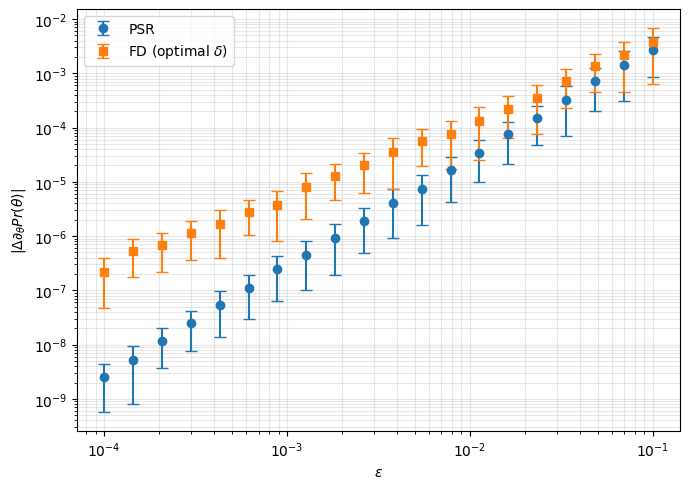

In [3]:
df = pd.read_csv("phase_noise_results.csv")

phase_errors = df["phase_error"].to_numpy()
psr_mean = df["psr_mean"].to_numpy()
psr_std = df["psr_std"].to_numpy()

finite_cols = [
    col for col in df.columns
    if col.startswith("finite_mean_delta_")
]

deltas = np.array([
    float(col.replace("finite_mean_delta_", ""))
    for col in finite_cols
])

finite_mean = df[finite_cols].to_numpy()

finite_std_cols = [
    f"finite_std_delta_{delta:.0e}" for delta in deltas
]

finite_std = df[finite_std_cols].to_numpy()

optimal_indices = np.argmin(finite_mean, axis=1)

optimal_deltas = deltas[optimal_indices]

optimal_fd_errors = finite_mean[
    np.arange(len(phase_errors)),
    optimal_indices
]

optimal_fd_std = finite_std[
    np.arange(len(phase_errors)),
    optimal_indices
]

optimal_df = pd.DataFrame({
    "phase_error": phase_errors,
    "psr_error": psr_mean,
    "psr_std": psr_std,
    "optimal_delta": optimal_deltas,
    "optimal_fd_error": optimal_fd_errors,
    "optimal_fd_std": optimal_fd_std,
})

optimal_df.to_csv(
    "optimal_delta_phase_noise.csv",
    index=False
)

plt.figure(figsize=(7, 5))

plt.errorbar(
    phase_errors,
    psr_mean,
    yerr=psr_std,
    fmt="o",
    capsize=4,
    label="PSR"
)

plt.errorbar(
    phase_errors,
    optimal_fd_errors,
    yerr=optimal_fd_std,
    fmt="s",
    capsize=4,
    label=r"FD (optimal $\delta$)"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"$\epsilon$")
plt.ylabel(r"$|\Delta\partial_\theta Pr(\theta)|$")

plt.grid(
    True,
    which="both",
    alpha=0.3
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "psr_vs_optimal_fd.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()